# Natural Gas Consumption Forecasting with Holt-Winters

Time series analysis and forecasting of **monthly natural gas consumption in the United States**, using data from the Federal Reserve Bank of St. Louis (FRED).

**Objectives**
1. Explore the historical consumption trend and its monthly seasonality
2. Train additive and multiplicative Holt-Winters models
3. Compare forecasts against actual data using MAPE, MAE and RMSE

*Developed as part of the MBA in Artificial Intelligence & Analytics Applied to Business — FGV.*

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotnine import ggplot, aes, geom_line, labs, theme_minimal, theme, element_text
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

## 2. Data loading

Source: [FRED — NATURALGAS series](https://fred.stlouisfed.org/series/NATURALGAS), natural gas consumption in billions of cubic feet. The data is downloaded directly as CSV from FRED.

In [2]:
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=NATURALGAS"

df = pd.read_csv(FRED_URL, parse_dates=[0], na_values=".")
df.columns = ["Date", "NaturalGas"]
df = df[df["Date"] >= "2000-01-01"].dropna().reset_index(drop=True)

print(f"Observations: {len(df)}")
print(f"Period: {df['Date'].min().date()} to {df['Date'].max().date()}")
df.head()

Observations: 319
Period: 2000-01-01 to 2026-07-01


,Date,NaturalGas
0,2000-01-01,2510.5
1,2000-02-01,2330.7
2,2000-03-01,2050.6
3,2000-04-01,1783.3
4,2000-05-01,1632.9


In [3]:
# Save a local copy of the dataset
Path("../data").mkdir(exist_ok=True)
df.to_excel("../data/natural_gas_fred.xlsx", index=False)

## 3. Exploratory visualization

### 3.1 Static chart (ggplot style)

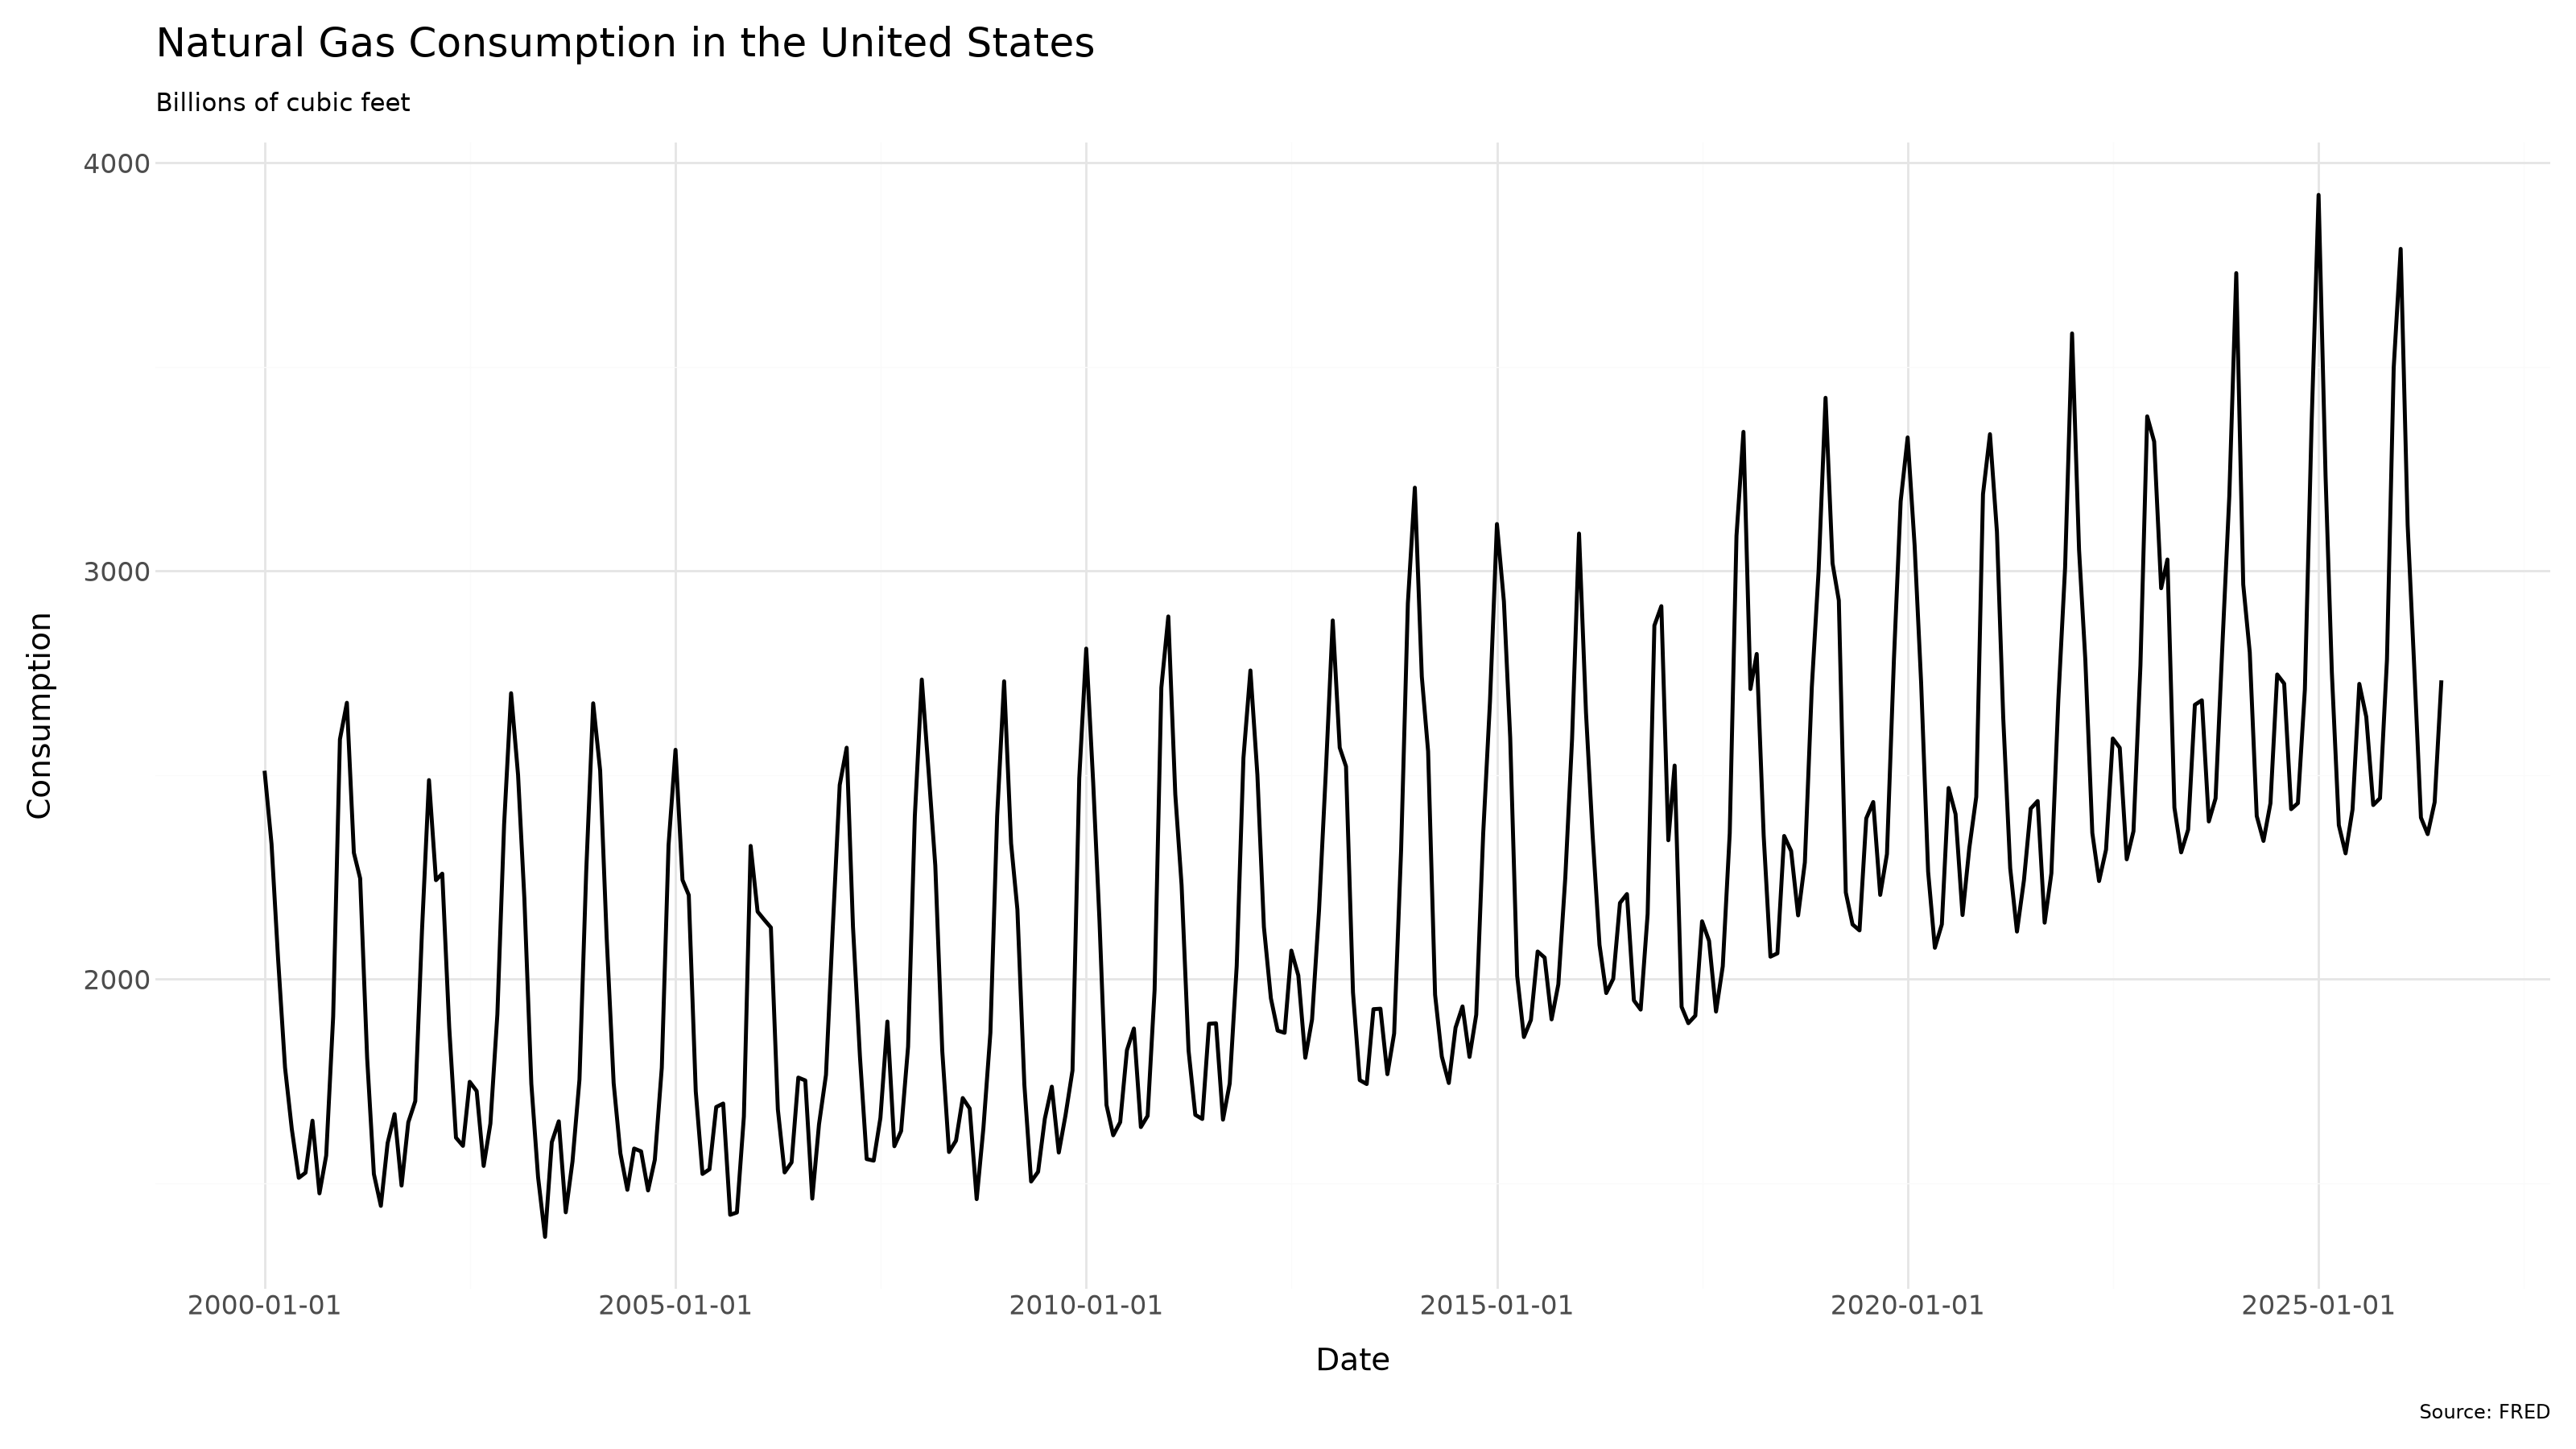

In [4]:
(
    ggplot(df, aes(x="Date", y="NaturalGas"))
    + geom_line(size=1)
    + labs(
        title="Natural Gas Consumption in the United States",
        subtitle="Billions of cubic feet",
        x="Date",
        y="Consumption",
        caption="Source: FRED"
    )
    + theme_minimal()
    + theme(
        figure_size=(16, 9),
        plot_title=element_text(size=18),
        axis_title=element_text(size=14),
        axis_text=element_text(size=12)
    )
)

### 3.2 Interactive chart (Plotly)

In [5]:
fig = px.line(
    df,
    x="Date",
    y="NaturalGas",
    title="Natural Gas Consumption (FRED) — billions of cubic feet",
    template="simple_white"
)
fig.update_layout(
    width=1100,
    height=600,
    title_font_size=20,
    font=dict(size=13),
    hovermode="x unified"
)
fig.show()

### 3.3 Seaborn chart

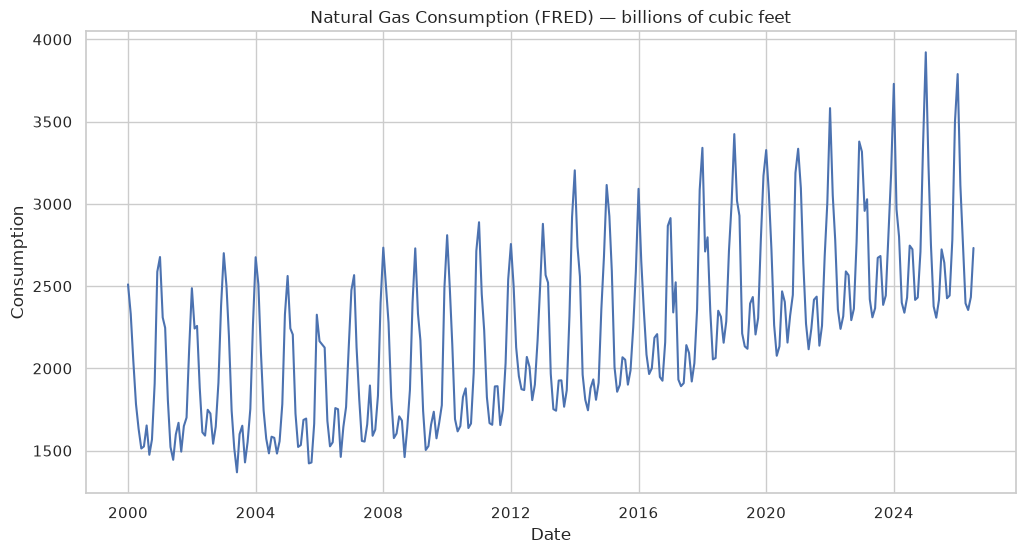

In [6]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x="Date", y="NaturalGas")
plt.title("Natural Gas Consumption (FRED) — billions of cubic feet")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.show()

## 4. Seasonality analysis

US natural gas consumption is typically highest in winter, driven by heating demand, with a secondary peak in summer from power generation. The boxplot below shows the distribution of consumption for each month. This yearly pattern is why the models use `seasonal_periods=12`.

In [7]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df["Month"] = df["Date"].dt.month.map(dict(enumerate(month_order, start=1)))

fig = px.box(
    df,
    x="Month",
    y="NaturalGas",
    category_orders={"Month": month_order},
    title="Monthly Seasonality of Natural Gas Consumption (billions of cubic feet)",
    points="outliers"
)
fig.update_traces(line_color="black", fillcolor="olive")
fig.update_layout(template="presentation", width=1050, height=700)
fig.show()

## 5. Train / test split

- **Training set:** January 2020 to December 2024 (60 months)
- **Test set:** January 2025 onwards

The series is set to a monthly frequency (`MS` = month start) so the models and forecasts share the same date index.

In [8]:
series = df.set_index("Date")["NaturalGas"].asfreq("MS")

train = series["2020-01-01":"2024-12-31"]
test = series["2025-01-01":]

print(f"Train: {train.index.min().date()} to {train.index.max().date()} ({len(train)} months)")
print(f"Test:  {test.index.min().date()} to {test.index.max().date()} ({len(test)} months)")

Train: 2020-01-01 to 2024-12-01 (60 months)
Test:  2025-01-01 to 2026-07-01 (19 months)


In [9]:
def mape(y_true, y_pred):
    """Mean Absolute Percentage Error, in %."""
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100


def evaluate(y_true, y_pred):
    """Returns MAPE, MAE and RMSE for a forecast."""
    return {
        "MAPE (%)": mape(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }


def plot_forecast(forecasts, title):
    """Plots training data, test data and one or more forecasts.

    forecasts: dict in the format {label: (forecast_series, color)}
    """
    plt.figure(figsize=(15, 8))
    plt.plot(train.index, train, label="Training data")
    plt.plot(test.index, test, label="Test data (actual)", color="orange")
    for label, (values, color) in forecasts.items():
        plt.plot(values.index, values, label=label, linestyle="--", color=color)
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("Natural gas consumption")
    plt.legend()
    plt.grid(True)
    plt.show()

## 6. Modelling with Holt-Winters

### 6.1 Additive model

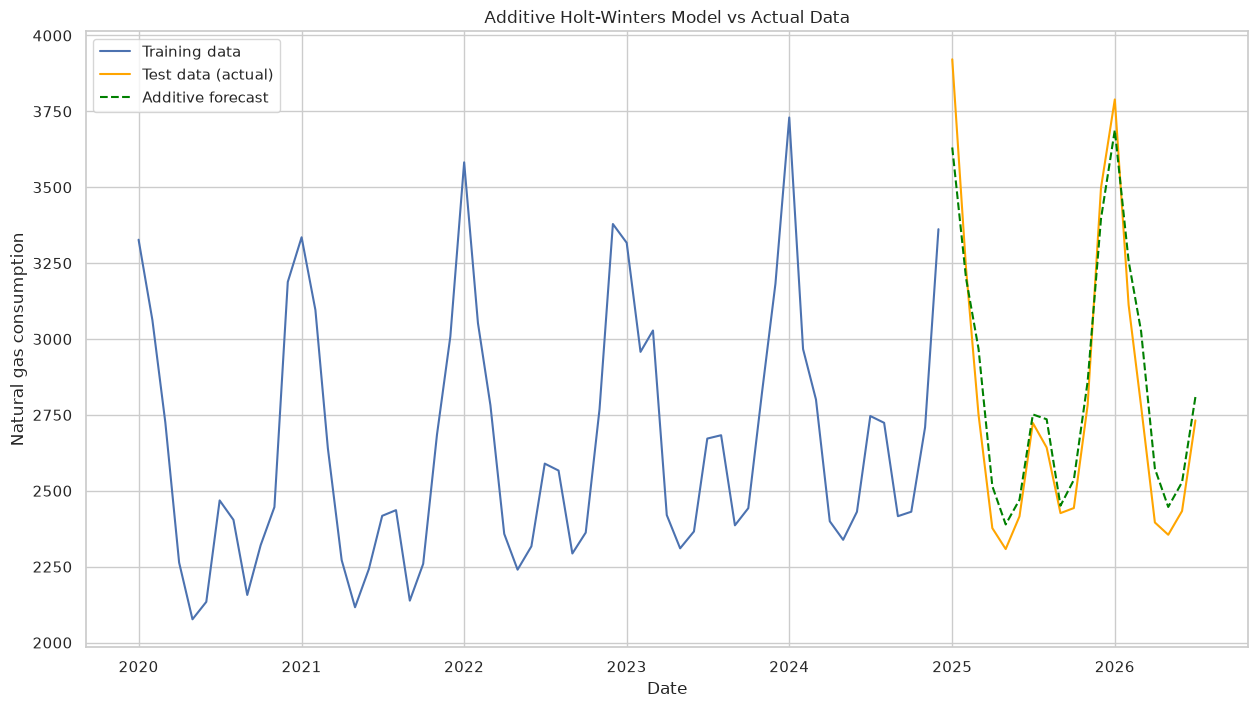

In [10]:
model_add = ExponentialSmoothing(
    train,
    seasonal_periods=12,   # monthly seasonality
    trend="add",           # additive trend
    seasonal="add",        # additive seasonality
    initialization_method="estimated"
).fit()

forecast_add = model_add.forecast(len(test))

plot_forecast({"Additive forecast": (forecast_add, "green")},
              "Additive Holt-Winters Model vs Actual Data")

### 6.2 Multiplicative model

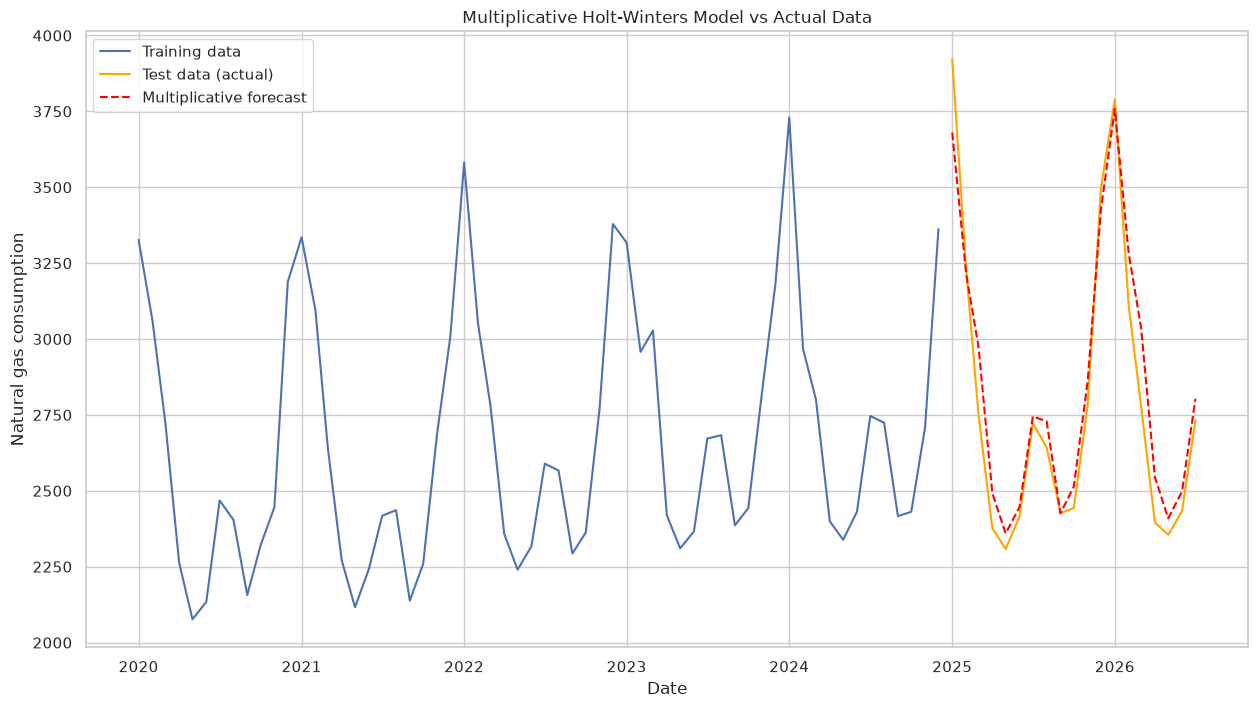

In [11]:
model_mul = ExponentialSmoothing(
    train,
    seasonal_periods=12,
    trend="mul",           # multiplicative trend
    seasonal="mul",        # multiplicative seasonality
    initialization_method="estimated"
).fit()

forecast_mul = model_mul.forecast(len(test))

plot_forecast({"Multiplicative forecast": (forecast_mul, "red")},
              "Multiplicative Holt-Winters Model vs Actual Data")

## 7. Model comparison

In [12]:
results = pd.DataFrame({
    "Additive": evaluate(test, forecast_add),
    "Multiplicative": evaluate(test, forecast_mul),
}).T.round(2)

best = results["MAPE (%)"].idxmin()
print(f"Best model by MAPE: {best} ({results.loc[best, 'MAPE (%)']:.2f}%)")
results

Best model by MAPE: Multiplicative (3.38%)


,MAPE (%),MAE,RMSE
Additive,4.06,113.92,134.31
Multiplicative,3.38,94.89,121.39


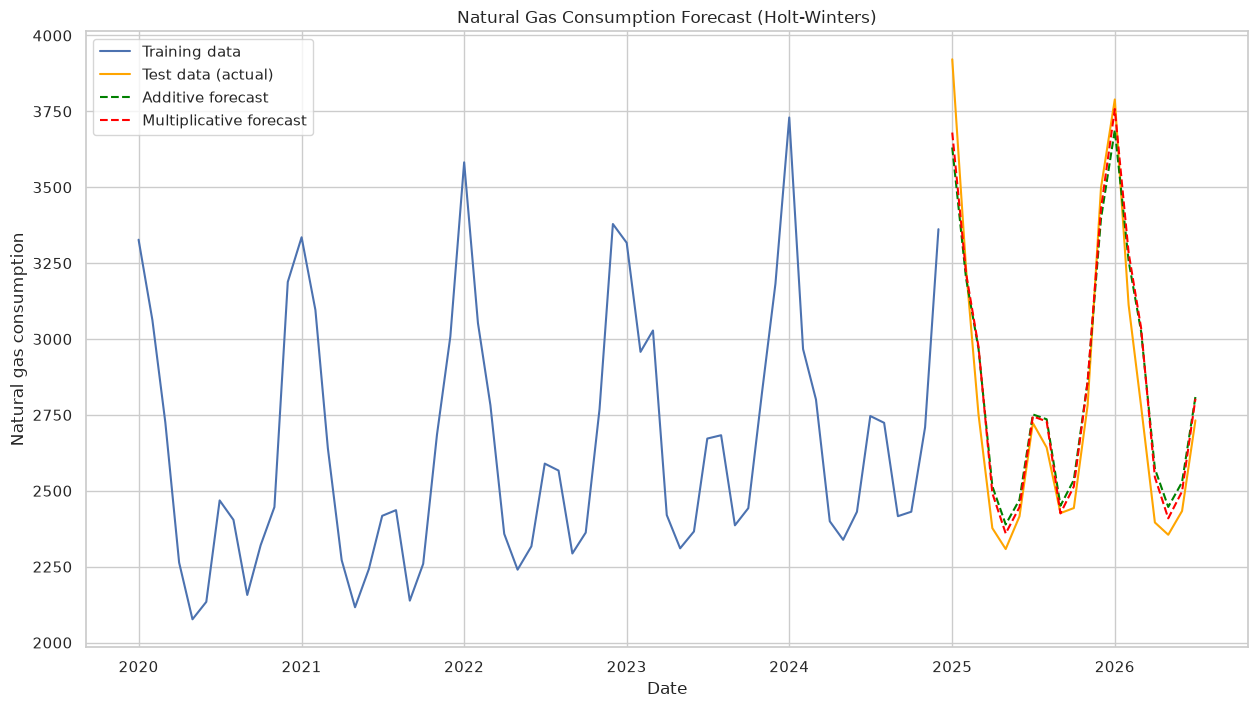

In [13]:
plot_forecast(
    {
        "Additive forecast": (forecast_add, "green"),
        "Multiplicative forecast": (forecast_mul, "red"),
    },
    "Natural Gas Consumption Forecast (Holt-Winters)"
)